# 03 — Prédiction de la limite d'élasticité : modèles supervisés et semi-supervisé

**Rappel de la stratégie (notebook 02)** : régression de la limite d'élasticité à partir de
la recette (composition, réglages, traitement thermique), évaluée sur des publications
jamais vues.

Plan :
1. Nettoyage complet et pré-traitement
2. Protocole de validation croisée
3. Les quatre modèles vus en cours et le gradient boosting
4. Résultats et comparaison
5. Approche semi-supervisée : self-training
6. Conclusion

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

RESULTS = Path.cwd().parent / "results"
RESULTS.mkdir(exist_ok=True)

sys.path.insert(0, str(Path.cwd().parent / "src"))
import preprocessing
import welddb

sns.set_theme(style="whitegrid", context="notebook")
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")
os.environ["PYTHONWARNINGS"] = "ignore:`sklearn.utils.parallel.delayed`:UserWarning"  # processus parallèles
TARGET = "yield_strength_MPa"

## 1. Nettoyage complet et pré-traitement

Le code est dans `src/preprocessing.py`. Il applique les décisions des notebooks 01 et 02 :

| Étape | Traitement | Justification |
|---|---|---|
| Format brut | `N` → manquant, `<x` → x, plages → milieu, etc. | Fait au chargement (`src/welddb.py`) |
| Valeurs en ppm < 1 | → manquantes | Probablement saisies en % massique (erreur d'unité) |
| Vanadium `<5` (9 lignes) | → 0,0005 % | Limite de détection exprimée en ppm dans une colonne en % massique (5 % de V serait absurde) |
| Co, W, Sn, As, Sb | écartées | Renseignées sur moins de 20 % des lignes étiquetées |
| Ni, Cr, Mo, V, Cu, Ti, Al, B, Nb manquants | → 0 | Élément d'alliage non mentionné = non ajouté volontairement |
| Autres numériques manquants (O, N, courant, tension…) | → médiane | Toujours présents dans une soudure : 0 n'aurait pas de sens |
| Type de soudure, AC/DC, polarité | one-hot ; manquant → « inconnu » ; catégories de moins de 10 lignes regroupées | Les modèles demandent des nombres ; trop peu de lignes pour apprendre les catégories rares |
| Variables numériques | standardisation (moyenne 0, écart-type 1) | Unités et échelles très différentes (ppm, %, A, °C) ; indispensable pour k-NN et SVR |

**Pour éviter les fuites d'information**, la médiane et la standardisation sont calculées
uniquement sur les données d'entraînement de chaque pli. C'est automatique car le
pré-traitement est la première étape d'un `Pipeline` scikit-learn.

In [2]:
df = welddb.load()
labelled = df[df[TARGET].notna()].reset_index(drop=True)

X = preprocessing.clean(labelled)
y = labelled[TARGET].to_numpy()
groups = labelled["publication"].to_numpy()

n_suspect = sum(df[c].between(0, 1, inclusive="neither").sum() for c in welddb.COMPOSITION_PPM)
print(f"Valeurs ppm suspectes (< 1) mises en manquant : {n_suspect}")
print(f"Lignes étiquetées : {len(X)}, publications : {len(set(groups))}")
print(f"Variables d'entrée : {X.shape[1]} -> {preprocessing.make_preprocessor().fit_transform(X).shape[1]} après one-hot")
X.head()

Valeurs ppm suspectes (< 1) mises en manquant : 313
Lignes étiquetées : 780, publications : 42
Variables d'entrée : 25 -> 32 après one-hot


,Ni,Cr,Mo,V,Cu,Ti_ppm,Al_ppm,B_ppm,Nb_ppm,C,...,N_ppm,current_A,voltage_V,heat_input_kJmm,interpass_temp_C,pwht_temp_C,pwht_time_h,weld_type,ac_dc,polarity
0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.037,...,NaN,170.0,21.0,1.0,200.0,250.0,14.0,MMA,DC,+
1,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.037,...,NaN,170.0,21.0,1.0,200.0,580.0,2.0,MMA,DC,+
2,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.037,...,NaN,170.0,21.0,1.0,200.0,250.0,14.0,MMA,DC,+
3,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.037,...,NaN,170.0,21.0,1.0,200.0,580.0,2.0,MMA,DC,+
4,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.044,...,NaN,170.0,21.0,1.0,200.0,250.0,14.0,MMA,DC,+


## 2. Protocole de validation croisée

**Validation croisée groupée par publication.** Les 780 lignes sont réparties en 5 plis
(`GroupKFold`) de sorte que toutes les lignes d'une même publication soient dans le même
pli. Chaque modèle est entraîné sur 4 plis et testé sur le 5ᵉ, cinq fois. Le notebook 02 a
montré qu'un découpage aléatoire divisait l'erreur par deux de façon trompeuse.

**Validation croisée imbriquée pour les hyperparamètres.** k-NN, SVR, forêt aléatoire et gradient boosting ont
des hyperparamètres (nombre de voisins, etc.). Si on les choisissait en regardant le score
sur le pli de test, ce score serait optimiste. Dans chaque pli d'entraînement, on fait donc
une **seconde validation croisée groupée** (4 plis) pour choisir les hyperparamètres
(`GridSearchCV`), puis on évalue le modèle retenu sur le pli de test, jamais utilisé
jusque-là.

```
Pour chaque pli externe (5) :
    entraînement (4/5 des publications)  ──►  GridSearchCV avec GroupKFold(4)  ──►  meilleurs hyperparamètres
    test (1/5 des publications)           ──►  évaluation du modèle retenu
```

**Métriques** (yᵢ valeur mesurée, ŷᵢ valeur prédite, ȳ moyenne, n lignes de test) :

- **RMSE** (métrique principale) = √( (1/n) Σ (yᵢ − ŷᵢ)² ), en MPa. Pénalise fortement les
  grosses erreurs, qui sont les plus dangereuses pour dimensionner une structure.
- **MAE** = (1/n) Σ |yᵢ − ŷᵢ|, en MPa. L'erreur « typique », moins sensible aux valeurs
  extrêmes.
- **R²** = 1 − Σ (yᵢ − ŷᵢ)² / Σ (yᵢ − ȳ)². Part de la variance expliquée : 0 = pas mieux que
  prédire la moyenne, 1 = parfait, négatif = pire que la moyenne.

**Référence** : un modèle qui prédit toujours la moyenne d'entraînement (`DummyRegressor`).
Tout modèle utile doit faire mieux.

## 3. Les modèles

En plus des quatre modèles vus en cours, on teste le **gradient boosting d'arbres** (GBRT),
la méthode d'ensemble de référence sur les données tabulaires, déjà utilisée au notebook 02
pour l'importance des variables.

| Modèle | Principe | Hyperparamètres testés |
|---|---|---|
| **Régression linéaire** | ŷ = w₀ + Σ wⱼ xⱼ, coefficients par moindres carrés | aucun |
| **k plus proches voisins** | moyenne de la cible des k soudures les plus proches dans l'espace des entrées standardisées | k ∈ {5, 10, 20, 40, 80}, pondération uniforme ou par l'inverse de la distance |
| **SVR** (noyau gaussien) | régression à vaste marge : ignore les erreurs < ε, fonction non linéaire via le noyau | C ∈ {0,1 ; 1 ; 10 ; 100}, γ ∈ {auto (`scale`) ; 0,01 ; 0,1}, ε ∈ {0,05 ; 0,2} |
| **Forêt aléatoire** | moyenne de 300 arbres de décision, chacun appris sur un échantillon bootstrap avec un sous-ensemble aléatoire de variables | part des variables par nœud ∈ {0,33 ; 0,66 ; 1}, taille minimale des feuilles ∈ {1, 3, 5} |
| **Gradient boosting** (GBRT) | somme de 300 petits arbres appris l'un après l'autre, chacun corrigeant les erreurs (résidus) des précédents ; la contribution de chaque arbre est réduite par le taux d'apprentissage, et chaque arbre est appris sur 80 % des lignes tirées au hasard | taux d'apprentissage ∈ {0,03 ; 0,1}, profondeur maximale des arbres ∈ {2, 3, 5} |

La cible est aussi standardisée pendant l'entraînement (`TransformedTargetRegressor`),
puis les prédictions sont remises en MPa. C'est nécessaire pour le SVR, dont C et ε dépendent
de l'échelle de la cible, et sans effet pour les autres modèles.

In [3]:
def make_model(estimator):
    pipe = Pipeline([("prep", preprocessing.make_preprocessor()), ("model", estimator)])
    return TransformedTargetRegressor(regressor=pipe, transformer=StandardScaler())

P = "regressor__model__"
MODELS = {
    "Moyenne (référence)": (DummyRegressor(), {}),
    "Régression linéaire": (LinearRegression(), {}),
    "k-NN": (KNeighborsRegressor(),
             {P + "n_neighbors": [5, 10, 20, 40, 80], P + "weights": ["uniform", "distance"]}),
    "SVR": (SVR(kernel="rbf"),
            {P + "C": [0.1, 1, 10, 100], P + "gamma": ["scale", 0.01, 0.1], P + "epsilon": [0.05, 0.2]}),
    "Forêt aléatoire": (RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=-1),
                        {P + "max_features": [0.33, 0.66, 1.0], P + "min_samples_leaf": [1, 3, 5]}),
    "Gradient boosting": (GradientBoostingRegressor(n_estimators=300, subsample=0.8, random_state=0),
                          {P + "learning_rate": [0.03, 0.1], P + "max_depth": [2, 3, 5]}),
}

In [4]:
outer_cv = GroupKFold(n_splits=5)
inner_cv = GroupKFold(n_splits=4)

scores, best_params = [], []
oof = {name: np.full(len(y), np.nan) for name in MODELS}  # prédictions hors pli

start = time.time()
for fold, (train, test) in enumerate(outer_cv.split(X, y, groups)):
    for name, (estimator, grid) in MODELS.items():
        model = make_model(estimator)
        if grid:
            search = GridSearchCV(model, grid, cv=inner_cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
            search.fit(X.iloc[train], y[train], groups=groups[train])
            model = search.best_estimator_
            best_params.append({"pli": fold, "modèle": name,
                                **{k.removeprefix(P): v for k, v in search.best_params_.items()}})
        else:
            model.fit(X.iloc[train], y[train])
        pred = model.predict(X.iloc[test])
        oof[name][test] = pred
        scores.append({"pli": fold, "modèle": name,
                       "RMSE": root_mean_squared_error(y[test], pred),
                       "MAE": mean_absolute_error(y[test], pred),
                       "R²": r2_score(y[test], pred)})
print(f"Durée : {time.time() - start:.0f} s")
scores = pd.DataFrame(scores)

/private/tmp/claude-501/-Users-philemon-Centrale-3A-ApprAuto-Projet/f737d978-09f2-4281-a909-629ac742f948/scratchpad/venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/private/tmp/claude-501/-Users-philemon-Centrale-3A-ApprAuto-Projet/f737d978-09f2-4281-a909-629ac742f948/scratchpad/venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserWarning: `sklearn.utils.parallel.delayed` should be used with `sklearn.utils.parallel.Parallel` to make it possible to propagate the scikit-learn configuration of the current thread to the joblib workers.
  warnings.warn(
/private/tmp/claude-501/-Users-philemon-Centrale-3A-ApprAuto-Projet/f737d978-09f2-4281-a909-629ac742f948/scratchpad/venv/lib/python3.13/site-packages/sklearn/utils/parallel.py:144: UserW

Durée : 25 s


## 4. Résultats et comparaison

In [5]:
order = list(MODELS)
summary = scores.groupby("modèle")[["RMSE", "MAE", "R²"]].agg(["mean", "std"]).loc[order]
summary.round(2)

RMSE           MAE           R²      
                       mean    std   mean    std  mean   std
modèle                                                      
Moyenne (référence)   92.59  16.08  72.08  10.48 -0.06  0.06
Régression linéaire  105.27  22.14  80.45  22.24 -0.41  0.45
k-NN                  88.07  25.87  66.43  18.97  0.05  0.32
SVR                   66.75  11.83  48.83  10.09  0.45  0.07
Forêt aléatoire       67.48  11.72  49.66   8.78  0.44  0.05
Gradient boosting     62.93   7.33  46.12   6.01  0.50  0.09

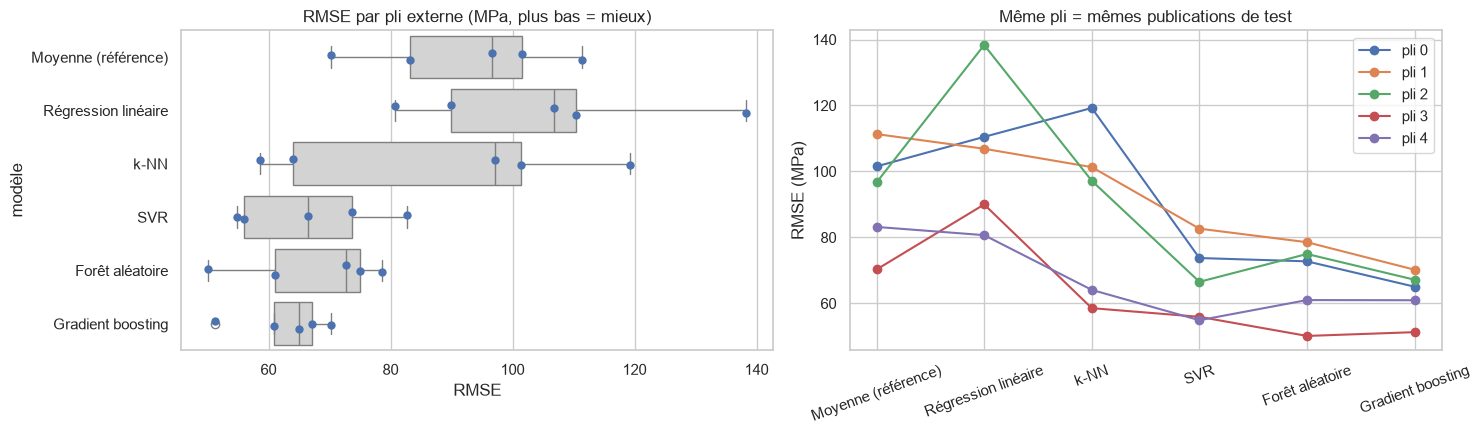

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
sns.boxplot(data=scores, y="modèle", x="RMSE", order=order, ax=axes[0], color="lightgrey")
sns.stripplot(data=scores, y="modèle", x="RMSE", order=order, ax=axes[0], color="C0", size=6)
axes[0].set_title("RMSE par pli externe (MPa, plus bas = mieux)")

wide = scores.pivot(index="pli", columns="modèle", values="RMSE")[order]
for fold, row in wide.iterrows():
    axes[1].plot(order, row.values, "o-", label=f"pli {fold}")
axes[1].set_ylabel("RMSE (MPa)"); axes[1].legend(); axes[1].tick_params(axis="x", rotation=20)
axes[1].set_title("Même pli = mêmes publications de test")
plt.tight_layout();

**Lecture.**
- Le **gradient boosting** est le meilleur modèle en moyenne (environ 63 MPa de RMSE,
  R² ≈ 0,50), et son RMSE est le plus régulier d'un pli à l'autre. Il gagne 3 plis sur 5
  face au SVR comme face à la forêt aléatoire (contre la forêt : une égalité, une défaite).
- La **forêt aléatoire** et le **SVR** sont nettement meilleurs que la référence et sont au
  même niveau en moyenne (environ 67 MPa de RMSE, R² ≈ 0,45).
- Le **k-NN** fait à peine mieux que la moyenne : toutes les variables standardisées comptent
  autant dans la distance, y compris celles qui n'influencent pas la cible (fléau de la
  dimension).
- La **régression linéaire** fait **pire que la moyenne** (R² négatif). Voir ci-dessous.
- L'écart d'un pli à l'autre est grand : certaines publications sont « faciles », d'autres
  « difficiles ». Le graphique de droite compare les modèles pli par pli : la forêt
  aléatoire gagne 3 plis, le SVR 2, avec des écarts de 1 à 9 MPa dans les deux sens. La
  différence entre les deux n'est **pas significative** : on les considère comme
  équivalents.

In [7]:
pd.DataFrame(best_params).set_index(["modèle", "pli"]).sort_index()

n_neighbors   weights     C  epsilon  gamma  \
modèle            pli                                                
Forêt aléatoire   0            NaN       NaN   NaN      NaN    NaN   
                  1            NaN       NaN   NaN      NaN    NaN   
                  2            NaN       NaN   NaN      NaN    NaN   
                  3            NaN       NaN   NaN      NaN    NaN   
                  4            NaN       NaN   NaN      NaN    NaN   
Gradient boosting 0            NaN       NaN   NaN      NaN    NaN   
                  1            NaN       NaN   NaN      NaN    NaN   
                  2            NaN       NaN   NaN      NaN    NaN   
                  3            NaN       NaN   NaN      NaN    NaN   
                  4            NaN       NaN   NaN      NaN    NaN   
SVR               0            NaN       NaN  10.0     0.20  scale   
                  1            NaN       NaN   1.0     0.05   0.01   
                  2            NaN       NaN  10.0     0.20   0.01   
                  3            NaN       NaN  10.0     0.05  scale   
                  4            NaN       NaN  10.0     0.20   0.01   
k-NN              0           40.0  distance   NaN      NaN    NaN   
                  1           80.0  distance   NaN      NaN    NaN   
                  2           20.0  distance   NaN      NaN    NaN   
                  3           80.0  distance   NaN      NaN    NaN   
                  4           80.0  distance   NaN      NaN    NaN   

                       max_features  min_samples_leaf  learning_rate  \
modèle            pli                                                  
Forêt aléatoire   0            0.33               1.0            NaN   
                  1            0.33               3.0            NaN   
                  2            0.66               1.0            NaN   
                  3            0.33               1.0            NaN   
                  4            0.33               1.0            NaN   
Gradient boosting 0             NaN               NaN            0.1   
                  1             NaN               NaN            0.1   
                  2             NaN               NaN            0.1   
                  3             NaN               NaN            0.1   
                  4             NaN               NaN            0.1   
SVR               0             NaN               NaN            NaN   
                  1             NaN               NaN            NaN   
                  2             NaN               NaN            NaN   
                  3             NaN               NaN            NaN   
                  4             NaN               NaN            NaN   
k-NN              0             NaN               NaN            NaN   
                  1             NaN               NaN            NaN   
                  2             NaN               NaN            NaN   
                  3             NaN               NaN            NaN   
                  4             NaN               NaN            NaN   

                       max_depth  
modèle            pli             
Forêt aléatoire   0          NaN  
                  1          NaN  
                  2          NaN  
                  3          NaN  
                  4          NaN  
Gradient boosting 0          2.0  
                  1          2.0  
                  2          2.0  
                  3          2.0  
                  4          2.0  
SVR               0          NaN  
                  1          NaN  
                  2          NaN  
                  3          NaN  
                  4          NaN  
k-NN              0          NaN  
                  1          NaN  
                  2          NaN  
                  3          NaN  
                  4          NaN

Les hyperparamètres choisis changent d'un pli à l'autre. Les performances sont donc peu
sensibles à ces choix sur la grille testée. Pour le k-NN, le nombre de voisins retenu est
souvent grand : le modèle se rapproche d'une moyenne, ce qui confirme qu'il trouve peu de
voisins réellement pertinents. Le gradient boosting retient toujours des arbres de profondeur 2
avec un taux d'apprentissage de 0,1 : des arbres très simples suffisent, chacun captant des
interactions entre deux variables au plus.

### Prédictions hors pli

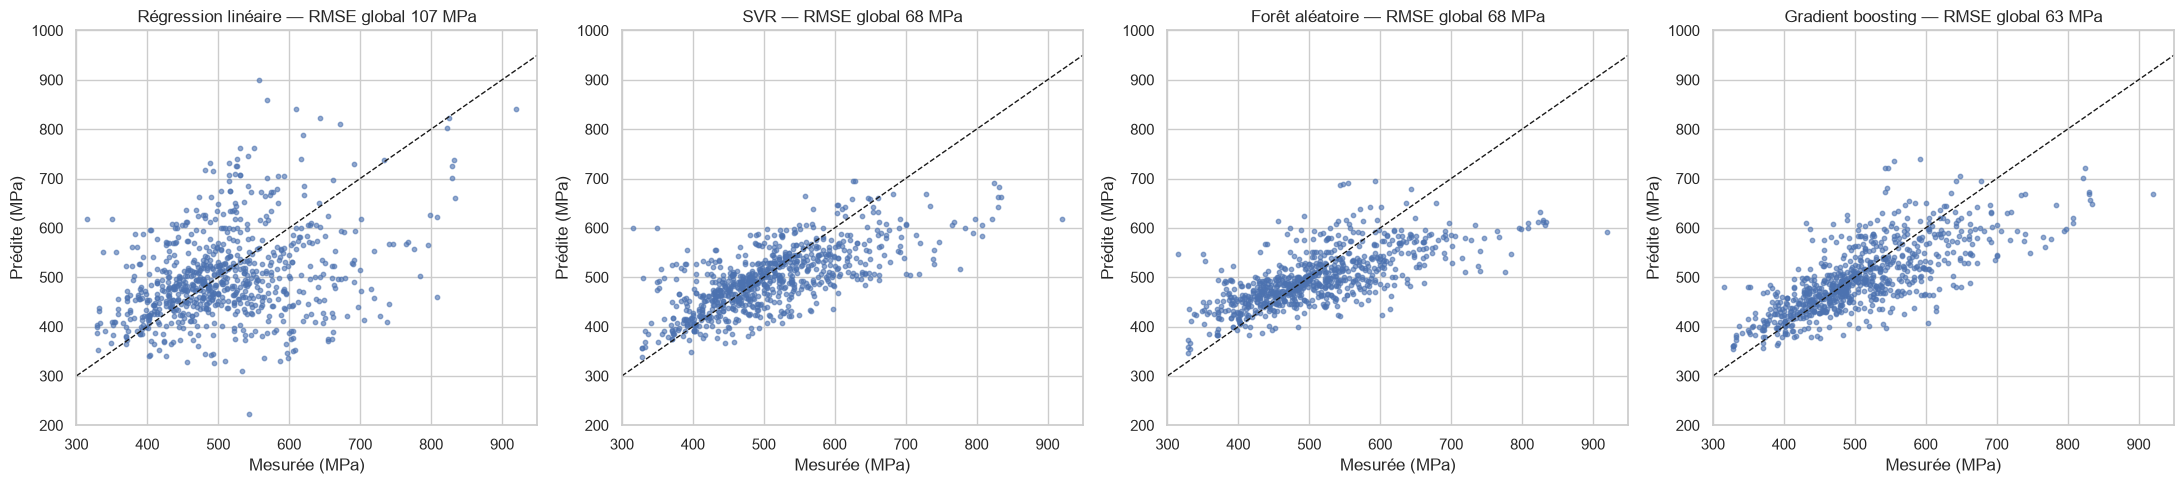

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
lims = [300, 950]
for ax, name in zip(axes, ["Régression linéaire", "SVR", "Forêt aléatoire", "Gradient boosting"]):
    ax.scatter(y, oof[name], s=10, alpha=0.6)
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_xlim(lims); ax.set_ylim(200, 1000)
    ax.set_xlabel("Mesurée (MPa)"); ax.set_ylabel("Prédite (MPa)")
    ax.set_title(f"{name} — RMSE global {root_mean_squared_error(y, oof[name]):.0f} MPa")
plt.tight_layout();

Les modèles **sous-estiment les soudures très résistantes** (> 700 MPa) : elles sont rares et
viennent de quelques publications, donc souvent absentes de l'entraînement quand leur
publication est en test.

### Pourquoi la régression linéaire échoue-t-elle ?

On regarde ses plus grosses erreurs :

In [9]:
worst = (labelled.assign(prédite=oof["Régression linéaire"].round(0),
                         erreur=(oof["Régression linéaire"] - y).round(0))
         .reindex((oof["Régression linéaire"] - y).__abs__().argsort()[::-1][:8]))
worst[["weld_id", "Cr", "Mo", "pwht_temp_C", "weld_type", TARGET, "prédite", "erreur"]]

,weld_id,Cr,Mo,pwht_temp_C,weld_type,yield_strength_MPa,prédite,erreur
655,Wolst-1974-AS1,2.20,NaN,690.0,MMA,473.0,104.0,-369.0
128,Evans-Cr/CMn-1989-2.3D-aw,2.36,NaN,250.0,MMA,808.0,459.0,-349.0
86,Evans-B/9Cr1Mo-1994-CM61,8.99,1.03,750.0,MMA,558.0,900.0,342.0
654,Wolst-1974-AS0,2.30,NaN,690.0,MMA,392.0,61.0,-331.0
126,Evans-Cr/CMn-1989-2.3C-aw,2.32,NaN,250.0,MMA,738.0,409.0,-329.0
656,Wolst-1974-AS2,2.00,NaN,690.0,MMA,543.0,223.0,-320.0
606,EPRI-TR-101394s-E9GT4,8.57,0.98,746.0,GTAA,728.0,421.0,-307.0
669,Inag&-1966-B,2.06,1.08,720.0,SA,315.0,618.0,303.0


Les plus grosses erreurs concernent toutes des aciers au chrome (2 à 9 % de Cr), alors que
la grande majorité des soudures de la base n'en contient presque pas. Certaines prédictions
sont physiquement absurdes : 61 MPa ou 104 MPa pour des soudures mesurées à 392 et 473 MPa.
Quand la publication de ces aciers est en test, l'entraînement contient très peu de
soudures comparables. Le modèle linéaire suppose que chaque variable a un effet **additif et
constant** : « +1 % de Cr = +x MPa », quel que soit le reste. Or, en métallurgie, l'effet
d'un élément dépend du traitement thermique et des autres éléments (un acier au Cr revenu
à 700 °C n'a pas la même résistance qu'à l'état brut de soudage). Le modèle
**extrapole** alors de façon linéaire hors du domaine qu'il a vu, et produit des valeurs
aberrantes. La forêt aléatoire, au contraire, ne prédit jamais en dehors de la plage des
valeurs vues : ses erreurs restent bornées.

## 5. Approche semi-supervisée

### 5.1 Motivation

La moitié des lignes de la base (872 sur 1 652) n'a pas de limite d'élasticité mesurée,
mais leur recette est connue. L'**apprentissage semi-supervisé** cherche à exploiter ces
entrées non étiquetées pour mieux apprendre la relation recette → propriété
[van Engelen & Hoos, 2020].

### 5.2 Méthodes envisagées

| Famille | Principe | Adapté ici ? |
|---|---|---|
| **Self-training** [Yarowsky, 1995 ; Triguero et al., 2015] | Un modèle prédit des « pseudo-étiquettes » pour les données non étiquetées ; on ajoute les plus fiables à l'entraînement et on recommence | Oui : fonctionne avec n'importe quel régresseur |
| **Co-training / COREG** [Zhou & Li, 2005] | Deux k-NN (distances différentes) s'étiquettent mutuellement des exemples | Possible, mais repose sur le k-NN, notre modèle le plus faible |
| Propagation de labels [Zhu & Ghahramani, 2002] | Diffusion des étiquettes dans un graphe de similarité | Conçue pour la classification |
| Méthodes profondes (consistency, MixMatch…) | Régularisation de réseaux de neurones | Hors du cadre du cours, peu de données |

### 5.3 Choix : self-training avec forêt aléatoire

- **Le meilleur modèle supervisé est la forêt aléatoire** : on part de lui.
- **La forêt fournit naturellement une mesure de confiance** : l'écart-type des prédictions
  de ses 300 arbres. Si les arbres sont d'accord, la pseudo-étiquette est probablement fiable.
- **Simple à expliquer et à reproduire.**
- Le gradient boosting fait un peu mieux en supervisé, mais il ne fournit pas cette mesure
  de confiance : ses arbres sont appris les uns à partir des autres, leurs prédictions ne
  sont pas des estimations indépendantes dont l'écart aurait un sens.

Algorithme (5 itérations) :
1. entraîner la forêt sur les données étiquetées ;
2. prédire les données non étiquetées et calculer l'écart-type entre arbres ;
3. ajouter à l'entraînement les 20 % les plus sûrs (écart-type le plus faible), avec leur
   prédiction comme étiquette ;
4. recommencer à l'étape 1.

**Évaluation honnête** : même validation croisée groupée par publication. Les lignes non
étiquetées des publications de test sont exclues de l'entraînement. La forêt utilise des
hyperparamètres fixes (`max_features=0.33`, `min_samples_leaf=1`, les plus souvent retenus
ci-dessus) pour isoler l'effet du semi-supervisé.

In [10]:
def make_forest():
    return Pipeline([("prep", preprocessing.make_preprocessor()),
                     ("model", RandomForestRegressor(n_estimators=300, max_features=0.33,
                                                     random_state=0, n_jobs=-1))])


def tree_predictions(forest, X):
    """Moyenne et écart-type des prédictions des arbres.

    Écart-type faible = arbres d'accord = pseudo-étiquette fiable. Le calcul arbre par
    arbre, dans un ordre fixe, rend les résultats exactement reproductibles.
    """
    Z = forest.named_steps["prep"].transform(X)
    per_tree = np.array([tree.predict(Z) for tree in forest.named_steps["model"].estimators_])
    return per_tree.mean(axis=0), per_tree.std(axis=0)


def self_training(X_lab, y_lab, X_unlab, n_iter=5, share=0.2):
    X_lab, y_lab, X_unlab = X_lab.copy(), y_lab.copy(), X_unlab.copy()
    for _ in range(n_iter):
        forest = make_forest().fit(X_lab, y_lab)
        if len(X_unlab) == 0:
            break
        pseudo, spread = tree_predictions(forest, X_unlab)
        most_confident = np.argsort(spread, kind="stable")[: max(1, int(share * len(X_unlab)))]
        X_lab = pd.concat([X_lab, X_unlab.iloc[most_confident]])
        y_lab = np.concatenate([y_lab, pseudo[most_confident]])
        X_unlab = X_unlab.drop(X_unlab.index[most_confident])
    return make_forest().fit(X_lab, y_lab)

### 5.4 Expérience

Le semi-supervisé est surtout utile quand **les étiquettes sont rares**. On compare donc la
forêt supervisée et le self-training avec 100 %, 50 %, 25 % et 10 % des étiquettes
d'entraînement. Les étiquettes retirées rejoignent les données non étiquetées, comme si
elles n'avaient pas été mesurées. Pour les fractions < 100 %, le tirage est répété avec 2
graines aléatoires.

In [11]:
X_all = preprocessing.clean(df)
y_all = df[TARGET].to_numpy()
g_all = df["publication"].to_numpy()
lab_idx = np.flatnonzero(~np.isnan(y_all))
unlab_idx = np.flatnonzero(np.isnan(y_all))

rows = []
start = time.time()
for fold, (train, test) in enumerate(outer_cv.split(lab_idx, groups=g_all[lab_idx])):
    train, test = lab_idx[train], lab_idx[test]
    unlab_pool = unlab_idx[~np.isin(g_all[unlab_idx], g_all[test])]  # pas de publication de test
    for share in [1.0, 0.5, 0.25, 0.1]:
        for seed in ([0] if share == 1.0 else [0, 1]):
            keep = train if share == 1.0 else np.random.default_rng(seed).choice(train, int(share * len(train)), replace=False)
            hidden = np.setdiff1d(train, keep)
            X_unlab = X_all.iloc[np.concatenate([unlab_pool, hidden])]

            supervised = make_forest().fit(X_all.iloc[keep], y_all[keep])
            semi = self_training(X_all.iloc[keep], y_all[keep], X_unlab)
            for name, model in [("Supervisé", supervised), ("Self-training", semi)]:
                rows.append({"pli": fold, "graine": seed, "part étiquetée": share, "méthode": name,
                             "RMSE": root_mean_squared_error(y_all[test], model.predict(X_all.iloc[test]))})
print(f"Durée : {time.time() - start:.0f} s")
semi_scores = pd.DataFrame(rows)

Durée : 45 s


méthode,Self-training,Supervisé,gain (MPa),self-training meilleur (% des cas)
part étiquetée,,,,
1.00,67.5,66.3,-1.3,40.0
0.50,70.1,68.7,-1.4,30.0
0.25,75.9,74.2,-1.7,10.0
0.10,79.8,77.7,-2.1,10.0


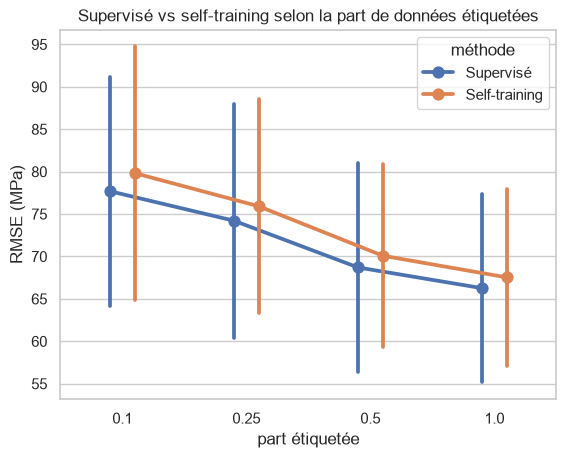

In [12]:
table = semi_scores.pivot_table(index="part étiquetée", columns="méthode", values="RMSE").sort_index(ascending=False)
table["gain (MPa)"] = table["Supervisé"] - table["Self-training"]
paired = semi_scores.pivot_table(index=["part étiquetée", "pli", "graine"], columns="méthode", values="RMSE")
table["self-training meilleur (% des cas)"] = (100 * (paired["Self-training"] < paired["Supervisé"])
                                                .groupby("part étiquetée").mean())
display(table.round(1))

ax = sns.pointplot(data=semi_scores, x="part étiquetée", y="RMSE", hue="méthode", order=[0.1, 0.25, 0.5, 1.0],
                   dodge=0.2, errorbar="sd")
ax.set_title("Supervisé vs self-training selon la part de données étiquetées")
ax.set_ylabel("RMSE (MPa)");

In [13]:
scores.to_csv(RESULTS / "ys_scores.csv", index=False)
semi_scores.to_csv(RESULTS / "ys_semi_scores.csv", index=False)
pd.DataFrame({"weld_id": labelled["weld_id"], "publication": groups, "mesure": y,
              **{f"pred_{k}": v for k, v in oof.items()}}).to_csv(RESULTS / "ys_oof.csv", index=False)
print("Résultats enregistrés dans", RESULTS)

Résultats enregistrés dans /Users/philemon/Centrale/3A/ApprAuto/Projet/soudure-ml-cs/results


### 5.5 Analyse

**Le self-training n'améliore pas la prédiction** : en moyenne, il est légèrement moins bon
que la forêt supervisée (1 à 2 MPa), quelle que soit la quantité d'étiquettes, et il ne
gagne que sur une minorité de plis. Trois raisons :

1. **Les données non étiquetées apportent peu d'information nouvelle.** Sur les 872 lignes
   sans limite d'élasticité, 489 ont exactement la même recette qu'une ligne étiquetée (la
   même soudure, mesurée en Charpy, cf. notebook 02). Leur pseudo-étiquette ne fait que
   recopier ce que le modèle sait déjà.
2. **La difficulté principale n'est pas le manque d'étiquettes, mais le changement de
   domaine entre publications.** L'erreur vient des publications de test qui explorent des
   compositions absentes de l'entraînement. Le self-training ajoute des pseudo-étiquettes
   là où la forêt est déjà sûre d'elle, c'est-à-dire dans les zones déjà bien couvertes, pas
   là où elle se trompe.
3. **Le modèle renforce ses propres biais** (*confirmation bias*) : une forêt réentraînée
   sur ses propres prédictions tend vers les mêmes prédictions, avec un léger lissage.

**Conclusion sur le semi-supervisé** : la méthode est pertinente sur le papier (la moitié
des données n'est pas étiquetée), mais les hypothèses qui la font fonctionner (des données
non étiquetées nombreuses, nouvelles et proches des zones d'incertitude) ne sont pas
vérifiées ici.

## 6. Conclusion

| Modèle | RMSE (MPa) | Commentaire |
|---|---|---|
| Moyenne | ~93 | référence |
| Régression linéaire | ~105 | extrapole mal, effets non additifs |
| k-NN | ~88 | distance polluée par les variables peu utiles |
| **SVR** | **~67** | **équivalent à la forêt aléatoire** |
| **Forêt aléatoire** | **~67** | **équivalent au SVR** |
| **Gradient boosting** | **~63** | **meilleur en moyenne, RMSE le plus régulier entre plis** |
| Forêt + self-training | 67 à 80 selon la part d'étiquettes | environ 1 à 2 MPa moins bon que le supervisé |

Pour la limite d'élasticité, le gradient boosting gagne environ 4 MPa sur le SVR et la forêt
aléatoire, qui sont équivalents entre eux. La forêt a un R² régulier d'un pli à l'autre et
n'extrapole pas de façon aberrante, le SVR a une erreur moyenne très légèrement plus faible. **Le choix final est fait au notebook 05**, en tenant
compte aussi de la résilience Charpy et des métriques de décision.

Une erreur d'environ 67 MPa sur des publications nouvelles reste élevée (la limite
d'élasticité varie de 315 à 920 MPa). Sur des soudures proches de celles déjà vues (même
publication), l'erreur est deux fois plus faible : le modèle est donc surtout fiable **à
l'intérieur du domaine de composition déjà exploré**.

**Prochaines étapes** : appliquer la même démarche à la résilience Charpy, puis interpréter le
modèle retenu pour formuler des recommandations.

### Références

- Yarowsky, D. (1995). *Unsupervised word sense disambiguation rivaling supervised methods*. ACL.
- Zhu, X., & Ghahramani, Z. (2002). *Learning from labeled and unlabeled data with label propagation*. CMU-CALD-02-107.
- Zhou, Z.-H., & Li, M. (2005). *Semi-supervised regression with co-training*. IJCAI.
- Triguero, I., García, S., & Herrera, F. (2015). *Self-labeled techniques for semi-supervised learning: taxonomy, software and empirical study*. Knowledge and Information Systems, 42(2).
- van Engelen, J. E., & Hoos, H. H. (2020). *A survey on semi-supervised learning*. Machine Learning, 109(2).